In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-08-20 16:04:38.837923: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-20 16:04:38.915033: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-20 16:04:38.915076: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-20 16:04:38.916786: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-20 16:04:38.928215: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-20 16:04:38.929014: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [3]:
import numpy as np
import tensorflow as tf

tfkl = tf.keras.layers
import keras

In [6]:
class AutocorrelationOnlyCritic(tf.keras.Model):
    
    def __init__(self, N_features, hidden_dim, embed_dim, layers, activation, dropout_rate=0):
        super(AutocorrelationOnlyCritic, self).__init__()

        self.sub_critics = []
        self.N_features = N_features
        for n in range(self.N_features):
            self.sub_critics.append(mds.SeparableCritic(hidden_dim, embed_dim, layers, activation, dropout_rate))
            
        self.f = tf.keras.Sequential([mds.mlp(10,10,3,'tanh'), tfkl.Dense(1)])
        self.g = tf.keras.Sequential([mds.mlp(10,10,3,'tanh'), tfkl.Dense(1)])
        self.pure = {'f':self.f, 'g':self.g} # for easy testing

    @tf.function
    def call(self, x, y):
        out = tfkl.add([self.sub_critics[n](x[:,n][:,None], y[:,n][:,None]) for n in range(self.N_features)]) + tf.transpose(self.f(x)) + self.g(y)
        # out = tfkl.add([self.sub_critics[n](x[:,n][:,None], y[:,n][:,None]) for n in range(self.N_features)])
        return out

In [8]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind

current stimulus is opticflow


In [11]:
V_width = 1
V_E_buffer = 5
E_width = 1
N_trials = 10

opt_params = {"track_quantities": True, "quiet": True, "iterations": 16}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

critic_params_ctl = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}

critic_params = {
    "N_features": D.N * V_width,
    "hidden_dim": 3,
    "embed_dim": 3,
    "layers": 2,
    "activation": "tanh",
}

shuffle_trial_per_time = False

# critic_params = {
#     "N_features": D.N * V_width,
#     "layers": 1,
#     "activation": "tanh",
# }

experiment_configuration_variables = {'mi_measurement_params', 'N_trials', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'critic_params', 'critic_params_ctl', 'shuffle_trial_per_time'}

In [12]:
D.reset()
D.trim(20)
# D.subset_features(range(10))
if shuffle_trial_per_time:
    D.shuffle_trial_per_time()
V, E = D.create_V_and_E_datasets(V_width,V_E_buffer,E_width,1)

## Run test

In [13]:
def test_model(critic_function):
    V.reset()
    E.reset()
    train_points, test_points = tools.generate_train_test_indices(V.P, 0.5)

    # training set
    V.subset_points(train_points)
    E.subset_points(train_points)
    
    _, weights = als.train_NCE(
        X=V.X,
        Y=E.X,
        critic_function=critic_function,
        **opt_params
    )

    # training set
    mi_train = als.MI_NCE(
        X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )

    # Measure InfoNCE for test
    V.reset()
    E.reset()
    V.subset_points(test_points)
    E.subset_points(test_points)
    mi_test = als.MI_NCE(
        X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )

    return mi_train, mi_test, weights

In [14]:
# critic_weights = []

experiment_dims = (N_trials,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

mi_averages_test_ctl = np.zeros(experiment_dims)
mi_averages_train_ctl = np.zeros(experiment_dims)
mi_stdevs_train_ctl = np.zeros(experiment_dims)
mi_stdevs_test_ctl = np.zeros(experiment_dims)

for n in range(N_trials):
    critic_function_ctl = mds.SeparableCritic(**critic_params_ctl)
    critic_function = AutocorrelationOnlyCritic(**critic_params)
    mi_train, mi_test, w = test_model(critic_function)
    # critic_weights.append(w)
    mi_train_ctl, mi_test_ctl, _ = test_model(critic_function_ctl)
    mi_averages_test[n] = mi_test["mi"]
    mi_stdevs_train[n] = mi_train["mi_stdev"]
    mi_averages_train[n] = mi_train["mi"]
    mi_stdevs_test[n] = mi_test["mi_stdev"]
    mi_averages_test_ctl[n] = mi_test_ctl["mi"]
    mi_stdevs_test_ctl[n] = mi_test_ctl["mi_stdev"]
    mi_averages_train_ctl[n] = mi_train_ctl["mi"]
    mi_stdevs_train_ctl[n] = mi_train_ctl["mi_stdev"]
    

2024-08-20 16:05:59.373517: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-08-20 16:05:59.374892: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## Save

In [15]:
# select variables
critic_type = type(critic_function)
critic_config = critic_function.get_config()
save_vars = {
    "mi_averages_train",
    "mi_averages_test",
    "mi_stdevs_train",
    "mi_stdevs_test",
    "mi_averages_train_ctl",
    "mi_averages_test_ctl",
    "mi_stdevs_train_ctl",
    "mi_stdevs_test_ctl",
    "critic_type",
    "critic_config"
}.union(experiment_configuration_variables)
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [16]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, '', strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')

stim = D.movname
save_directory = os.path.join(cur_directory, 'saved', stim)
full_file_path = os.path.join(save_directory, f'autocorrelations only {(V_width,V_E_buffer,E_width)}, hidden_dim:{critic_config["hidden_dim"]}, embed_dim:{critic_config["embed_dim"]}, layers:{critic_config["layers"]}, iter:{opt_params["iterations"]}, shuffle_trial_per_time:{shuffle_trial_per_time}, with pure.dat')
# full_file_path = os.path.join(save_directory, 'test.dat')
# print(f"will save to {save_directory}")
print(f"will save to {full_file_path}")

will save to /home/adam/Documents/projects/retina-past-future-ib/analyses/architecture tests/saved/opticflow/autocorrelations only (1, 5, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16, shuffle_trial_per_time:False, with pure.dat


In [17]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [ ]:
stim = 'opticflow'
setup = (1,0,1)
V_width, V_E_buffer, E_width = setup
hidden_dim = 3
embed_dim = 3
layers = 2

load_path = project_folder + '/analyses/architecture tests/saved/opticflow/autocorrelations only (1, 5, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16, shuffle_trial_per_time:False, with pure.dat'

# load_path = project_folder + 'analyses/architecture tests/saved/opticflow/autocorrelations only (1, 0, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16.dat'
# load_path = f'./saved/{stim}/autocorrelations only {setup}, hidden_dim:{hidden_dim}, embed_dim:{embed_dim}, layers:{layers}, iter:16 with pure.dat'
# load_path = project_folder + f'analyses/architecture tests/saved/{stim}/autocorrelations only (1, 0, 1), layers:6 new.dat'
# load_path = f'./saved/{stim}/autocorrelations only {setup}, hidden_dim:{hidden_dim}, embed_dim:{embed_dim}, layers:{layers} with pure.dat'
# load_path = f'./saved/{stim}/autocorrelations only {setup}, hidden_dim:{hidden_dim}, embed_dim:{embed_dim}, layers:{layers}.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)


In [19]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [20]:
average_test, stdevs_test = process_trials(data.mi_averages_test, data.mi_stdevs_test)
average_train, stdevs_train = process_trials(data.mi_averages_train, data.mi_stdevs_train)
average_test_ctl, stdevs_test_ctl = process_trials(data.mi_averages_test_ctl, data.mi_stdevs_test_ctl)
average_train_ctl, stdevs_train_ctl = process_trials(data.mi_averages_train_ctl, data.mi_stdevs_train_ctl)

(0.0, 0.8213101213544922)

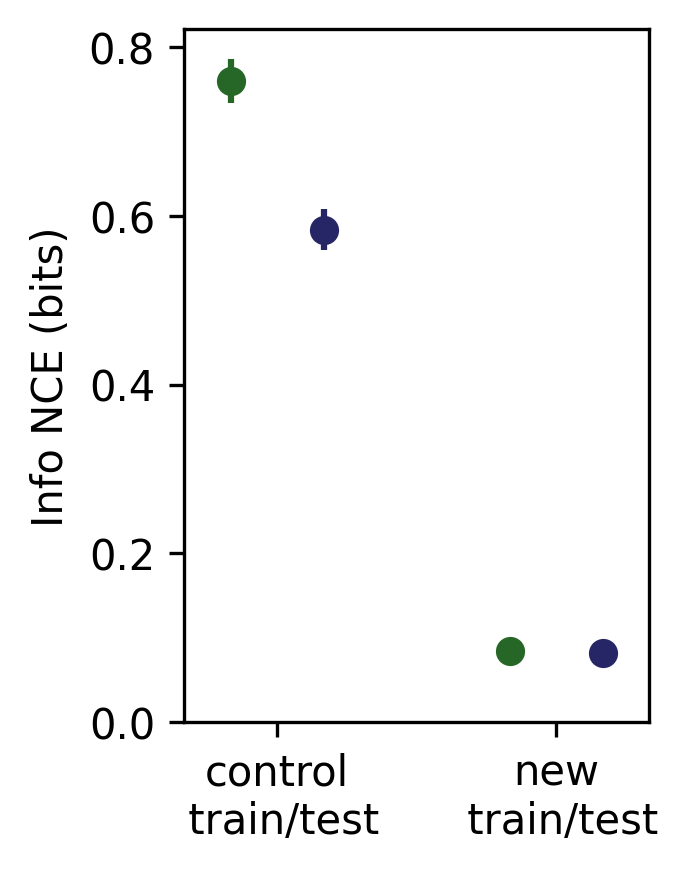

In [21]:
c1 = 0.3
c2 = 0.8
alp = 0.2
fig, ax = plt.subplots(dpi=300, figsize=[2,3])

locs = [0,1,3,4]
buffer = 0.5
l = 0.5
true_index = 1

ax.errorbar(locs[0], average_train_ctl / np.log(2), yerr=stdevs_train_ctl / np.log(2), marker='o', color=(c1*l,c2*l,c1*l))

ax.errorbar(locs[1], average_test_ctl / np.log(2), yerr=stdevs_test_ctl / np.log(2), marker='o', color=(c1*l,c1*l,c2*l))

ax.errorbar(locs[2], average_train / np.log(2), yerr=stdevs_train / np.log(2), marker='o', color=(c1*l,c2*l,c1*l))

ax.errorbar(locs[3], average_test / np.log(2), yerr=stdevs_test / np.log(2), marker='o', color=(c1*l,c1*l,c2*l))

ax.set_xticks(((locs[0] + locs[1]) / 2, (locs[2] + locs[3]) / 2 ))
ax.set_xticklabels(("control\n train/test", "new\n train/test"))
ax.set_xlim(locs[0]-buffer, locs[-1]+buffer)
ax.set_ylabel("Info NCE (bits)")
ax.set_ylim(0)
